# Integer rounding and implementation fidelity

We ask how four integer-rounding rules affect tracking of the shared agricultural futures benchmark across portfolio sizes. We select a rule only at the frozen **$1m** reference AUM using daily-return Tracking RMSE in basis points. The other AUMs are descriptive robustness checks. All results below use the **real, frozen Section 0 handoff**, not synthetic fixtures.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "config/project.yaml").is_file() and (p / "data/section0/freeze.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Markdown, Image
from src.validation.schemas import load_project_config
from src.rounding.analysis import load_rounding_experiment, analyse_rounding
from src.rounding.exports import write_outputs, chart_export_matches
config = load_project_config(ROOT / "config/project.yaml")
experiment = load_rounding_experiment(ROOT / "data/section0", config)

## Frozen experiment

The loader checks the Section 0 output hashes, consumed-input hashes, calendar/catalogue identities, common mask and reference non-binding capacity. It rejects changes rather than rebuilding Section 0. The first return is (27 February, 2 March 2026]; earlier observations are warm-up only. Exact-contract benchmark quantities and post-capacity fractional targets come from the same frozen experiment.

In [2]:
dates = experiment.freeze["frozen_dates"]
reference = experiment.freeze["preflight"]["references"]["rounding"]
assert len(dates) == 148 and reference == 1_000_000
assert config["aum_grid_usd"] == [1_000_000, 10_000_000, 100_000_000, 1_000_000_000]
display(pd.DataFrame([{
    "first_return": dates[0], "last_return": dates[-1], "common_dates": len(dates),
    "reference_AUM_USD": reference, "reference_capacity_binding": False,
    "project_spec_version": config["project_spec_version"],
}]))

,first_return,last_return,common_dates,reference_AUM_USD,reference_capacity_binding,project_spec_version
0,2026-03-02,2026-09-30,148,1000000,False,8.0


## Methods and fixed assumptions

We compare nearest with half-up ties, toward zero (floor), away from zero (ceiling, with zero unchanged), and residual greedy. Greedy starts at floor and makes only the feasible one-contract addition giving the greatest strictly positive decrease in squared dollar-notional error. Ties follow ZC, ZS, ZW, then earlier maturity. There is no shared notional-budget constraint.

Only rounding varies. The baseline destination, −5-session timing, capacity targets/ceilings, equal commodity weights, fractional benchmark, contract values and accounting are fixed. At each AUM all four rules use the same fixed denominator and the same 148-date mask. The existing rounding engine is imported unchanged. No other strand's preferred method enters this experiment.

In [3]:
result = analyse_rounding(experiment)
assert result["data_kind"] == "real_frozen_databento_section0"
assert all(r["common_valid_dates"] == 148 for r in result["by_aum"])
# The adapter also checks nearest holdings/returns against the frozen baseline,
# benchmark returns against the frozen benchmark, and every capacity ceiling.
summary = pd.DataFrame(result["summary"])
grid = pd.DataFrame(result["by_aum"])
display(summary[["rule", "fixed_aum", "tracking_rmse_bps_daily", "common_valid_dates"]]
        .assign(tracking_rmse_bps_daily=lambda d: d.tracking_rmse_bps_daily.map(lambda x: f"{x:.6f}")))

,rule,fixed_aum,tracking_rmse_bps_daily,common_valid_dates
0,nearest,1000000,8.021906,148
1,toward_zero,1000000,7.664237,148
2,away_from_zero,1000000,12.462801,148
3,residual_greedy,1000000,8.021906,148


## Tracking RMSE across AUM

Lower daily-bp RMSE indicates better historical implementation fidelity. Values are rounded only for display; saved CSVs preserve the shared Decimal results. Selection uses $1m only.

rule,nearest,toward_zero,away_from_zero,residual_greedy
fixed_aum,,,,
1000000,8.021906,7.664237,12.462801,8.021906
10000000,7.258071,6.929645,7.618797,7.258071
100000000,7.248176,7.217197,7.286010,7.247607
1000000000,87.981363,87.981363,87.981363,87.981363


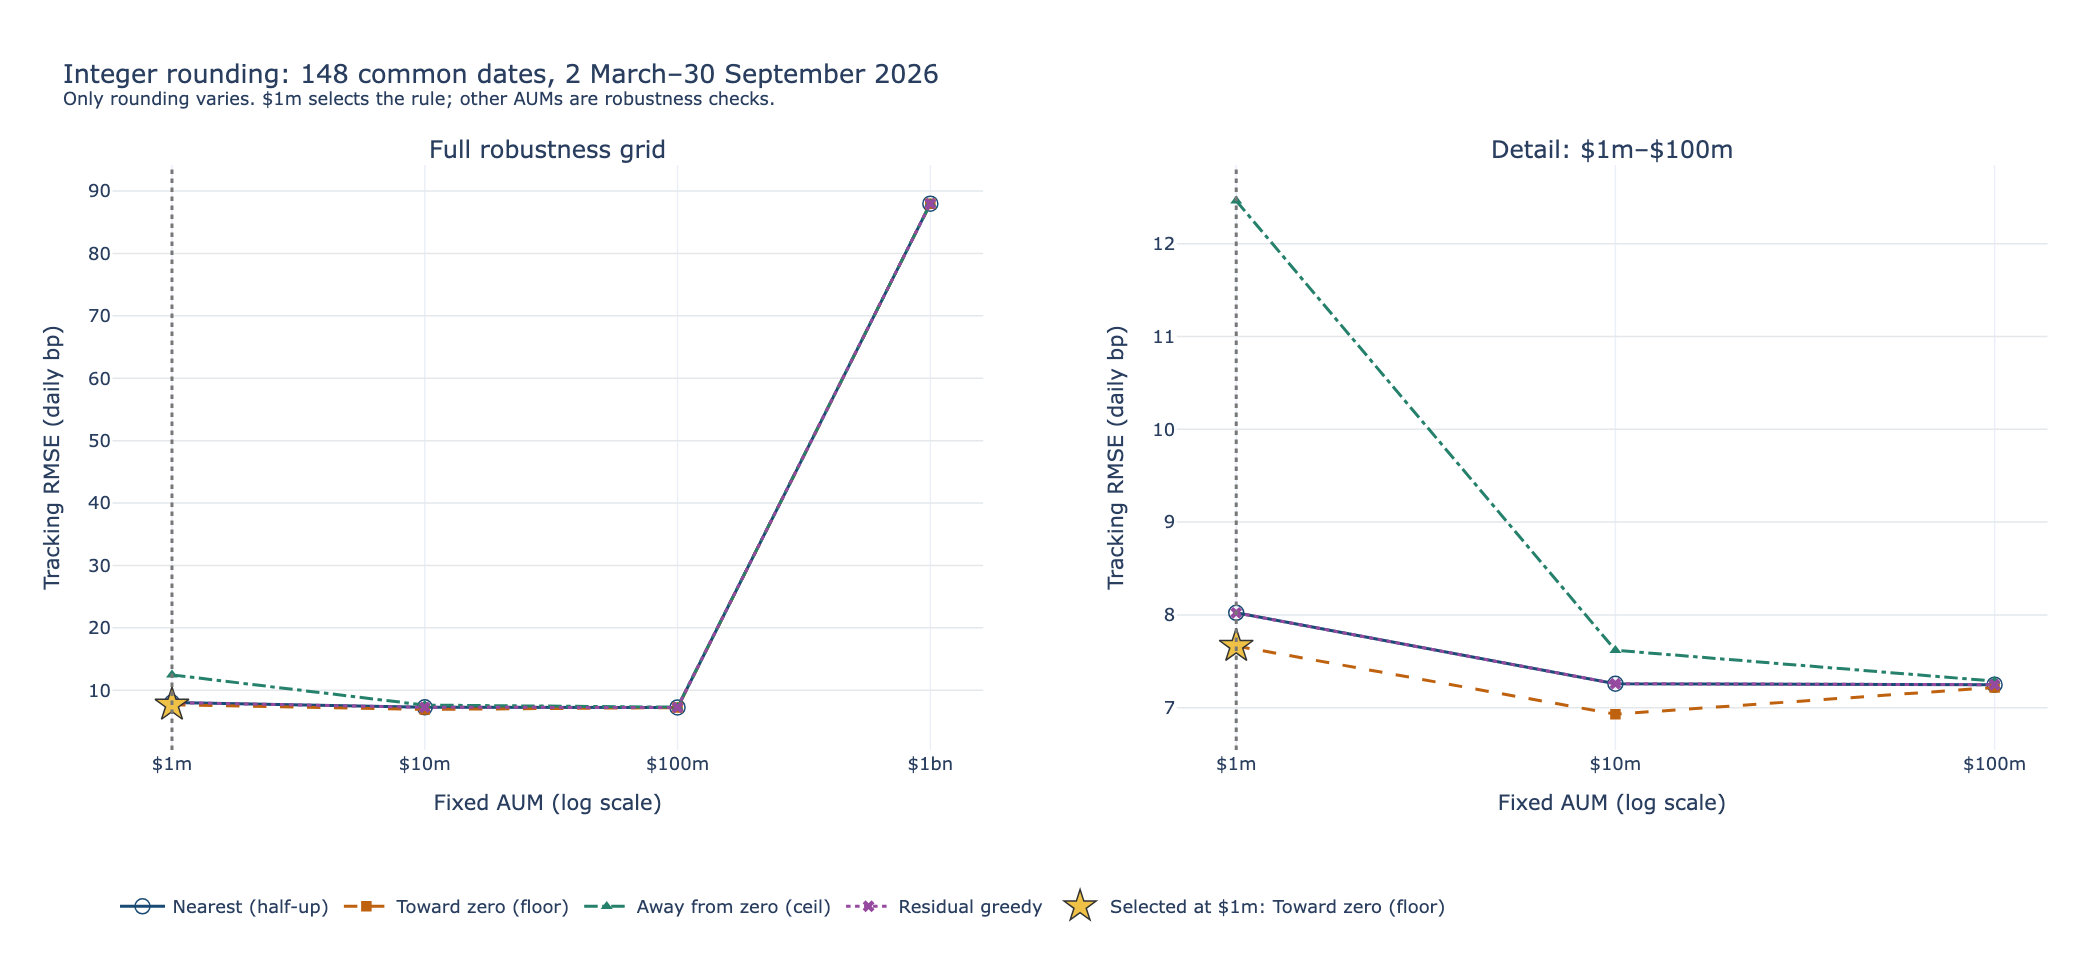

In [4]:
table = grid.pivot(index="fixed_aum", columns="rule", values="tracking_rmse_bps_daily")
table = table[["nearest", "toward_zero", "away_from_zero", "residual_greedy"]]
display(table.map(lambda x: f"{x:.6f}"))
output_dir = ROOT / "outputs/person4"
manifest = write_outputs(result, output_dir)
assert chart_export_matches(output_dir), "Export the current Plotly figure before using the saved PNG"
display(Image(filename=str(output_dir / "tracking_rmse_vs_aum.png")))

## Diagnostics and interpretation

Nearest and residual greedy coincide at $1m and $10m. At $100m, two exact-half targets produce two different contract quantities: half-up adds the contract, whereas greedy rejects the zero-improvement addition. At $1bn, all 444 commodity-date targets are capacity constrained and integral, so the four rounding rules produce the same holdings and RMSE.

Absolute benchmark tracking error also contains the maturity, timing and capacity effects held fixed across rules. It is not an isolated decomposition of rounding error. These diagnostics explain the comparison and do not form a second ranking metric.

In [5]:
display(grid.loc[grid.rule == "residual_greedy", [
    "fixed_aum", "positions", "positions_different_from_nearest", "exact_half_targets",
    "capacity_binding_positions"]])

,fixed_aum,positions,positions_different_from_nearest,exact_half_targets,capacity_binding_positions
3,1000000,444,0,0,0
7,10000000,444,0,0,0
11,100000000,444,2,2,0
15,1000000000,444,0,0,444


## Preferred rule

Differences **strictly below 0.1 daily bp** count as ties; exactly 0.1 bp does not. A tied baseline is preferred. Selection is confined to the frozen $1m reference and is not repeated at a different AUM. Findings are conditional on this historical sample and the fixed baseline assumptions.

In [6]:
selection = result["selection"]
nearest = next(r["tracking_rmse_bps_daily"] for r in result["summary"] if r["rule"] == "nearest")
selected = next(r["tracking_rmse_bps_daily"] for r in result["summary"]
                if r["rule"] == selection["preferred_rule"])
display(Markdown(f"**Selected: {selection['preferred_rule']} at $1m.** "
    f"Tracking RMSE: **{selected:.6f} daily bp**; improvement over nearest: "
    f"**{nearest-selected:.6f} daily bp**. Tie rule triggered: **{selection['tie_triggered']}**."))

**Selected: toward_zero at $1m.** Tracking RMSE: **7.664237 daily bp**; improvement over nearest: **0.357669 daily bp**. Tie rule triggered: **False**.

## Saved outputs and reproduction

Run from the repository root after `uv sync --locked`:

```sh
uv run --no-sync python -B scripts/run_person4.py --real
uv run --no-sync python -B -m unittest discover -s tests/unit -v
```

The CLI regenerates numerical outputs and the Plotly specification. The committed PNG is a browser export. To render a new PNG without adding packages, run with `--chart-html personal/rounding_chart.html`, open that self-contained HTML offline and use the camera button, then register the current export using `--chart-png PATH`. The saved image/hash receipt is checked against the regenerated specification. This is a manual image-export step, not a Python static renderer.

- [Reference results](../outputs/person4/rounding_summary.csv)
- [All AUM results](../outputs/person4/rounding_by_aum.csv)
- [Primary chart](../outputs/person4/tracking_rmse_vs_aum.png)
- [Daily returns](../outputs/person4/rounding_daily.csv) and [rounded holdings](../outputs/person4/rounded_holdings.csv)
- [Handoff](../outputs/person4/HANDOFF.md) and [input/output hashes](../outputs/person4/analysis_manifest.json)

This completes only the independent rounding comparison for [Issue #8](https://github.com/JacopoMichelacci/Futures_Class/issues/8). We do not combine strand selections, run Section 5, or include transaction costs or collateral yield in ranking. The separate `--fixtures` mode remains a synthetic demonstration.